# **Introducción al Fine-tuning de BETO para Detección de Sarcasmo en Español**
**Contexto General**
El análisis del sarcasmo en texto representa uno de los desafíos más complejos en el procesamiento del lenguaje natural (NLP), debido a su naturaleza pragmática y dependiente del contexto. El sarcasmo implica expresar lo contrario de lo que literalmente se dice, lo que requiere que los modelos computacionales comprendan no solo la semántica superficial, sino también las intenciones comunicativas subyacentes.

## **BETO: BERT en Español**

BETO (Bidirectional Encoder Representations from Transformers for Spanish) es una versión del modelo BERT de Google pre-entrenada específicamente en corpus de texto en español. Este modelo transformer bidireccional ha demostrado capacidades excepcionales para comprender el contexto lingüístico del español, capturando matices semánticos y sintácticos propios del idioma.

# **El Dataset: Ernesto-1997/Sarcastic_spanish_dataset**

Este dataset especializado contiene ejemplos de texto en español etiquetados para la clasificación de sarcasmo, proporcionando:
Textos sarcásticos: Expresiones que utilizan ironía, exageración o contradicción
Textos no sarcásticos: Expresiones literales y directas
Distribución balanceada: Permitiendo el entrenamiento de modelos robustos


In [ ]:
# Instalación de dependencias
!pip install transformers datasets evaluate seqeval torch pandas numpy matplotlib seaborn scikit-learn

# Importación de librerías
import os
import pandas as pd
import numpy as np
import re
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score
import evaluate

# Configuración de GPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"✅ GPU disponible: {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")
    print("⚠️ Usando CPU")

# Desactivar wandb si no se usa
os.environ["WANDB_DISABLED"] = "true"

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
✅ GPU disponible: NVIDIA GeForce RTX 4090


 Explicación
transformers: Librería principal de Hugging Face para modelos pre-entrenados
datasets: Para cargar y manipular datasets de manera eficiente
evaluate: Para métricas de evaluación estandarizadas
torch: Framework de deep learning de PyTorch
Configuración de GPU: Acelera el entrenamiento significativamente

📋Módulo 2: Carga y Exploración del Dataset
Objetivo
Cargar el dataset de sarcasmo y entender su estructura

📊 Estructura del dataset:
DatasetDict({
    train: Dataset({
        features: ['Texto', 'Sarcasmo'],
        num_rows: 15276
    })
    validation: Dataset({
        features: ['Texto', 'Sarcasmo'],
        num_rows: 3820
    })
})

🔍 Primeros ejemplos del training set:
{'Texto': ['Así son las grabaciones que comprometen a Fernández Díaz', 'Clan TV no sabe cómo preparar a los niños para la matanza de Peppa Pig', 'Muelas de elefante y casuarios: así aprenden ecología alumnos de Estepona', 'Qué bien, las discusiones solo fortalecen la relación, ¿verdad?', 'Clásicos en Alcalá dedica este año a Cervantes parte de su programación'], 'Sarcasmo': [1, 1, 0, 1, 0]}

📈 Dataset de entrenamiento: 15276 ejemplos
📈 Dataset de validación: 3820 ejemplos

🏷️ Distribución de etiquetas:
Sarcasmo
0    9162
1    6114
Name: count, dtype: int64


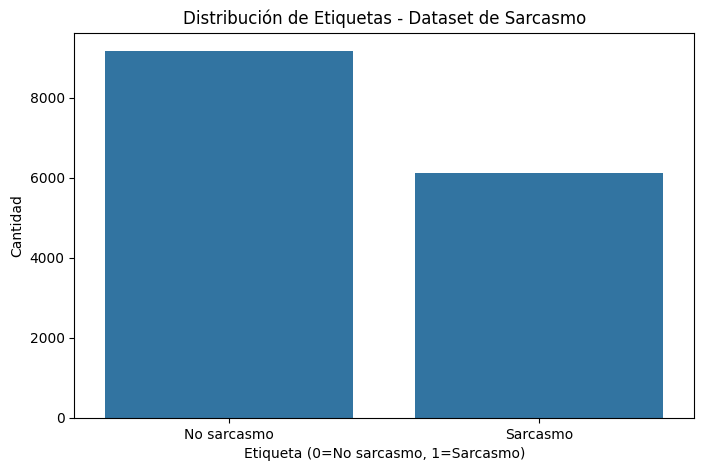


📝 Ejemplos por clase:

--- Clase: 1 ---
1. Así son las grabaciones que comprometen a Fernández Díaz...
2. Clan TV no sabe cómo preparar a los niños para la matanza de Peppa Pig...

--- Clase: 0 ---
1. Muelas de elefante y casuarios: así aprenden ecología alumnos de Estepona...
2. Clásicos en Alcalá dedica este año a Cervantes parte de su programación...


In [ ]:
# Cargar dataset desde Hugging Face
dataset = load_dataset("Ernesto-1997/Sarcastic_spanish_dataset")

# Ver estructura del dataset
print("📊 Estructura del dataset:")
print(dataset)

# Explorar el split de entrenamiento
print("\n🔍 Primeros ejemplos del training set:")
print(dataset["train"][:5])

# Convertir a DataFrame para análisis exploratorio
df_train = pd.DataFrame(dataset["train"])
df_val = pd.DataFrame(dataset["validation"]) if "validation" in dataset else None

# Estadísticas básicas
print(f"\n📈 Dataset de entrenamiento: {len(df_train)} ejemplos")
print(f"📈 Dataset de validación: {len(df_val) if df_val is not None else 'N/A'} ejemplos")

# Distribución de etiquetas
print("\n🏷️ Distribución de etiquetas:")
print(df_train["Sarcasmo"].value_counts())

# Visualizar distribución
plt.figure(figsize=(8, 5))
sns.countplot(data=df_train, x="Sarcasmo")   # ← cambiar "label" por "Sarcasmo"
plt.title("Distribución de Etiquetas - Dataset de Sarcasmo")
plt.xlabel("Etiqueta (0=No sarcasmo, 1=Sarcasmo)")
plt.ylabel("Cantidad")
plt.xticks([0, 1], ["No sarcasmo", "Sarcasmo"])
plt.show()

# Ejemplos de texto por clase
print("\n📝 Ejemplos por clase:")
for label in df_train["Sarcasmo"].unique():
    print(f"\n--- Clase: {label} ---")
    ejemplos = df_train[df_train["Sarcasmo"] == label]["Texto"].head(2)
    for i, texto in enumerate(ejemplos, 1):
        print(f"{i}. {texto[:150]}...")

📝 Explicación
load_dataset(): Carga automáticamente el dataset desde Hugging Face Hub
Análisis exploratorio: Permite entender la distribución de clases y calidad de los datos
Visualización: Ayuda a detectar desbalance de clases que podría afectar el entrenamiento
⚠️ Notas Importantes
Verificar si las etiquetas son binarias (0/1) o categóricas ("sarcasm"/"no_sarcasm")
Revisar longitud promedio de textos para configurar max_length apropiadamente

📋 Módulo 3: Preprocesamiento de Texto
Objetivo
Limpiar y normalizar los textos para mejorar el rendimiento del modelo.

📝 Explicación
Limpieza específica para redes sociales: Remueve ruido como URLs, menciones y emojis que no aportan significado semántico para sarcasmo
Preservación de caracteres españoles: Mantiene acentos y ñ que son importantes para el español
Normalización: Convierte a minúsculas para reducir dimensionalidad del vocabulario
⚠️ Notas Importantes
No eliminar signos de interrogación/exclamación: En sarcasmo, "¡Qué bien!" vs "Qué bien." pueden tener significados opuestos
Considerar mantener emojis: Algunos emojis son indicadores clave de sarcasmo (🙃, 😏, 🤔)

📋 Módulo 4: Tokenización con BETO
Objetivo
Convertir textos a tokens compatibles con el modelo BETO.

In [ ]:
# Configuración del tokenizer BETO
model_name = "dccuchile/bert-base-spanish-wwm-cased"
print(f"🔄 Cargando tokenizer: {model_name}")
tokenizer = AutoTokenizer.from_pretrained(model_name)

# --- CORRECCIÓN AQUÍ ---
# El dataset tiene columnas 'Texto' y 'Sarcasmo'.
# No limpiamos el texto, usamos 'Texto' directamente.
# Renombramos 'Sarcasmo' a 'labels' para que el Trainer lo entienda.

print("📂 Preparando datasets...")

# Dataset de Entrenamiento
dataset_train = Dataset.from_pandas(
    df_train[['Texto', 'Sarcasmo']].rename(columns={'Sarcasmo': 'labels'})
)

# Dataset de Validación
if df_val is not None:
    dataset_eval = Dataset.from_pandas(
        df_val[['Texto', 'Sarcasmo']].rename(columns={'Sarcasmo': 'labels'})
    )
else:
    # Si no hay validación, dividimos el train
    split_dataset = dataset_train.train_test_split(test_size=0.2, seed=42)
    dataset_train = split_dataset["train"]
    dataset_eval = split_dataset["test"]

# --- TOKENIZACIÓN ---
def tokenize_function(examples):
    return tokenizer(
        examples["Texto"],      # <--- Usamos la columna original 'Texto'
        padding="max_length",
        truncation=True,
        max_length=128,
        return_attention_mask=True
    )

print("🔤 Tokenizando dataset de entrenamiento...")
tokenized_train = dataset_train.map(tokenize_function, batched=True, remove_columns=["Texto"])

print("🔤 Tokenizando dataset de evaluación...")
tokenized_eval = dataset_eval.map(tokenize_function, batched=True, remove_columns=["Texto"])

# Verificar
print(f"✅ Formatos listos. Ejemplo etiqueta: {tokenized_train[0]['labels']}")

🔄 Cargando tokenizer: dccuchile/bert-base-spanish-wwm-cased
📂 Preparando datasets...
🔤 Tokenizando dataset de entrenamiento...


Map:   0%|          | 0/15276 [00:00<?, ? examples/s]

🔤 Tokenizando dataset de evaluación...


Map:   0%|          | 0/3820 [00:00<?, ? examples/s]

✅ Formatos listos. Ejemplo etiqueta: 1


📝 Explicación
BETO: BERT entrenado específicamente en corpus en español, ideal para tareas en nuestro idioma
Whole Word Masking (wwm): Técnica que enmascara palabras completas durante pre-entrenamiento, mejorando comprensión contextual
Padding y truncation: Aseguran que todas las secuencias tengan la misma longitud para procesamiento por lotes
⚠️ Notas Importantes
max_length=128: Ajustar según la longitud real de tus textos (ver estadísticas del Módulo 3)
batched=True: Acelera significativamente el procesamiento

📋 Módulo 5: Preparación del Modelo
Objetivo
Configurar el modelo BETO para clasificación binaria/multiclase.

In [ ]:
# Configuración del modelo
num_labels = len(df_train["Sarcasmo"].unique())  # Número de clases
label_names = df_train["Sarcasmo"].unique().tolist()

print(f"🎯 Configurando modelo para {num_labels} clases: {label_names}")

# Mapeo de etiquetas a IDs numéricos
label2id = {label: i for i, label in enumerate(label_names)}
id2label = {i: label for i, label in enumerate(label_names)}

print(f"🗂️ Mapeo de etiquetas: {label2id}")

# Cargar modelo pre-entrenado BETO para clasificación
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True  # Permite fine-tuning con diferente número de clases
)

# Mover modelo a GPU si está disponible
model = model.to(device)
print(f"✅ Modelo cargado en: {device}")

# Verificar arquitectura del modelo
print(f"\n🔧 Arquitectura del modelo:")
print(f"Tipo: {type(model).__name__}")
print(f"Parámetros totales: {sum(p.numel() for p in model.parameters()):,}")
print(f"Parámetros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

🎯 Configurando modelo para 2 clases: [1, 0]
🗂️ Mapeo de etiquetas: {1: 0, 0: 1}


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-cased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Modelo cargado en: cuda

🔧 Arquitectura del modelo:
Tipo: BertForSequenceClassification
Parámetros totales: 109,852,418
Parámetros entrenables: 109,852,418


📝 Explicación
AutoModelForSequenceClassification: Adapta BETO para tareas de clasificación añadiendo una capa lineal final
num_labels: Define el número de neuronas en la capa de salida (2 para binario, 3+ para multiclase)
label2id/id2label: Mapeos para convertir entre etiquetas originales y IDs numéricos
⚠️ Notas Importantes
ignore_mismatched_sizes=True: Necesario porque la capa de clasificación original de BETO tiene diferente tamaño
Fine-tuning: Solo se entrenan las capas finales + ajuste fino de BETO, no entrenamiento desde cero

📋 Módulo 6: Configuración de Métricas y Entrenamiento
Objetivo
Definir métricas de evaluación y parámetros de entrenamiento.

In [ ]:
# Cargar métricas de evaluación
metric = evaluate.load("f1")  # F1-score es clave para clasificación desbalanceada

def compute_metrics(eval_pred):
    """
    Calcula métricas de evaluación durante el entrenamiento
    """
    logits, labels = eval_pred

    # Convertir logits a predicciones (clase con mayor probabilidad)
    predictions = np.argmax(logits, axis=-1)

    # Calcular métricas
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='weighted', zero_division=0
    )
    acc = accuracy_score(labels, predictions)

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# Configuración de argumentos de entrenamiento
training_args = TrainingArguments(
    output_dir="beto-sarcasmo-spanish-2026",      # Directorio para guardar checkpoints
    num_train_epochs=5,                      # Número de épocas de entrenamiento
    per_device_train_batch_size=16,          # Batch size por GPU/CPU en train
    per_device_eval_batch_size=32,           # Batch size por GPU/CPU en eval
    warmup_steps=100,                        # Pasos de warmup para learning rate
    weight_decay=0.01,                       # Regularización L2
    logging_dir="./logs",                    # Directorio para logs
    logging_steps=50,                        # Frecuencia de logging
    eval_strategy="epoch",                   # Evaluar al final de cada época
    save_strategy="epoch",                   # Guardar checkpoint al final de cada época
    load_best_model_at_end=True,             # Cargar mejor modelo al finalizar
    metric_for_best_model="f1",              # Métrica para seleccionar mejor modelo
    greater_is_better=True,                  # F1 mayor es mejor
    learning_rate=2e-5,                      # Learning rate para fine-tuning
    fp16=torch.cuda.is_available(),          # Mixed precision si hay GPU
    report_to="none",                        # Desactivar reportes externos
    seed=42,                                 # Semilla para reproducibilidad
    push_to_hub=True,
)

print("⚙️ Configuración de entrenamiento:")
print(f"- Épocas: {training_args.num_train_epochs}")
print(f"- Batch size train: {training_args.per_device_train_batch_size}")
print(f"- Learning rate: {training_args.learning_rate}")
print(f"- Métrica principal: {training_args.metric_for_best_model}")

⚙️ Configuración de entrenamiento:
- Épocas: 5
- Batch size train: 16
- Learning rate: 2e-05
- Métrica principal: f1


📝 Explicación
F1-score weighted: Promedia F1 por clase ponderado por soporte, ideal para datasets desbalanceados
TrainingArguments: Configura todo el ciclo de entrenamiento de Hugging Face Trainer
warmup_steps: Previene inestabilidad al inicio del entrenamiento aumentando gradualmente el learning rate
⚠️ Notas Importantes
learning_rate=2e-5: Valor típico para fine-tuning de BERT; valores mayores pueden causar inestabilidad
fp16: Reduce uso de memoria ~50% y acelera entrenamiento en GPUs compatibles

📋 Módulo 7: Entrenamiento del Modelo
Objetivo
Ejecutar el proceso de fine-tuning con BETO.

In [ ]:
# Inicializar Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_eval,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    data_collator=DataCollatorWithPadding(tokenizer),  # Padding dinámico por batch
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]  # Early stopping
)

# Iniciar entrenamiento
print("🚀 Iniciando entrenamiento...")
train_result = trainer.train()

# Guardar métricas de entrenamiento
metrics = train_result.metrics
print("\n📊 Métricas finales de entrenamiento:")
for key, value in metrics.items():
    if not key.startswith("train_"):
        print(f"{key}: {value:.4f}")
trainer.push_to_hub()


C:\Users\Raul\AppData\Local\Temp\ipykernel_23112\3671735579.py:2: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


🚀 Iniciando entrenamiento...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.254900,0.252041,0.909686,0.910860,0.909686,0.910003
2,0.119900,0.294411,0.920681,0.921153,0.920681,0.920837
3,0.054000,0.402580,0.924084,0.923917,0.924084,0.923915
4,0.026100,0.509405,0.923298,0.923132,0.923298,0.923092
5,0.000800,0.547210,0.924346,0.924219,0.924346,0.924258



📊 Métricas finales de entrenamiento:
total_flos: 5024105602099200.0000
epoch: 5.0000


CommitInfo(commit_url='https://huggingface.co/raulgdp/beto-sarcasmo-spanish-2026/commit/b9e2cb503a887105866d87851a50d1eb6324fd82', commit_message='End of training', commit_description='', oid='b9e2cb503a887105866d87851a50d1eb6324fd82', pr_url=None, repo_url=RepoUrl('https://huggingface.co/raulgdp/beto-sarcasmo-spanish-2026', endpoint='https://huggingface.co', repo_type='model', repo_id='raulgdp/beto-sarcasmo-spanish-2026'), pr_revision=None, pr_num=None)

📝 Explicación
Trainer: Abstracción de Hugging Face que maneja el ciclo completo de entrenamiento/evaluación
DataCollatorWithPadding: Aplica padding solo hasta la secuencia más larga del batch (más eficiente que padding fijo)
EarlyStoppingCallback: Detiene el entrenamiento si la métrica no mejora por patience épocas, previniendo overfitting
⚠️ Notas Importantes
Monitorear pérdida de validación: Si eval_loss aumenta mientras train_loss disminuye, hay overfitting
Checkpointing: Los modelos se guardan al final de cada época por save_strategy="epoch"

📋 Módulo 8: Evaluación y Predicción
Objetivo
Evaluar el modelo entrenado y realizar predicciones en nuevos textos.

In [ ]:
ejemplos_sarcasmo = [
    "¡Qué divertido, otro lunes de trabajo! 🙃",
    "Me encanta cuando llueve el día que tengo planes al aire libre",
    "Obvio que aprobé el examen, estudié exactamente 5 minutos",
    "Qué sorpresa que el internet se cayó justo cuando iba a entregar la tarea",
    "Sí, porque claramente yo soy el experto en cocina gourmet 👨‍🍳",
    "Genial, se me olvidó la cartera... otra vez",
    "Ah sí, porque caminar 20 cuadras bajo el sol es exactamente lo que quería hacer hoy",
    "Qué bien, mi vuelo se retrasó 4 horas. Justo lo que necesitaba ✈️",
    "Claro, porque mi opinión es la más importante en esta reunión",
    "Me encanta cuando me interrumpen a mitad de una frase, es mi cosa favorita"
]

In [ ]:
ejemplos_no_sarcasmo = [
    "Hoy hace un día hermoso para salir a caminar",
    "Estoy muy feliz por tu logro, ¡felicidades!",
    "Necesito comprar leche y pan en el supermercado",
    "La película estuvo muy buena, la recomiendo",
    "Mañana tengo una reunión importante a las 9 AM",
    "Gracias por tu ayuda, realmente lo aprecio",
    "El tráfico está muy pesado hoy en la ciudad",
    "Me gusta mucho el café de esta cafetería",
    "Voy a estudiar para el examen de mañana",
    "El concierto de anoche fue increíble"
]

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch
import numpy as np

# Cargar modelo y tokenizer
model_name = "raulgdp/beto-sarcasmo-spanish-2026"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Configurar dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

def predecir_sarcasmo(textos, modelo, tokenizer, device):
    """
    Predice si un texto es sarcástico o no

    Args:
        textos: str o lista de str
        modelo: modelo cargado
        tokenizer: tokenizer cargado
        device: dispositivo de cómputo

    Returns:
        Lista de diccionarios con resultados
    """
    # Asegurar que sea lista
    if isinstance(textos, str):
        textos = [textos]

    # Tokenizar
    inputs = tokenizer(
        textos,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    # Predicción
    with torch.no_grad():
        outputs = modelo(**inputs)
        probabilities = torch.nn.functional.softmax(outputs.logits, dim=-1)
        predictions = torch.argmax(probabilities, dim=-1)

    # Mapeo de etiquetas (ajustar según tu entrenamiento)
    id2label = {0: "NO_SARCASMO", 1: "SARCASMO"}

    # Formatear resultados
    resultados = []
    for i, texto in enumerate(textos):
        pred_label = id2label[predictions[i].item()]
        resultados.append({
            "texto": texto,
            "prediccion": pred_label,
            "probabilidad_sarcasmo": probabilities[i][1].item(),
            "probabilidad_no_sarcasmo": probabilities[i][0].item(),
            "confianza": probabilities[i][predictions[i]].item()
        })

    return resultados if len(resultados) > 1 else resultados[0]

# Ejecutar predicciones
print("🔍 Probando ejemplos sarcásticos:")
for resultado in predecir_sarcasmo(ejemplos_sarcasmo[:5], model, tokenizer, device):
    print(f"\nTexto: {resultado['texto']}")
    print(f"Predicción: {resultado['prediccion']}")
    print(f"Confianza: {resultado['confianza']:.2%}")
    print(f"Prob. sarcasmo: {resultado['probabilidad_sarcasmo']:.2%}")

print("\n" + "="*60)
print("🔍 Probando ejemplos NO sarcásticos:")
for resultado in predecir_sarcasmo(ejemplos_no_sarcasmo[:5], model, tokenizer, device):
    print(f"\nTexto: {resultado['texto']}")
    print(f"Predicción: {resultado['prediccion']}")
    print(f"Confianza: {resultado['confianza']:.2%}")
    print(f"Prob. sarcasmo: {resultado['probabilidad_sarcasmo']:.2%}")

tokenizer_config.json: 0.00B [00:00, ?B/s]

D:\anaconda3\envs\chatbot\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Raul\.cache\huggingface\hub\models--raulgdp--beto-sarcasmo-spanish-2026. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/732 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/827 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/439M [00:00<?, ?B/s]

🔍 Probando ejemplos sarcásticos:

Texto: ¡Qué divertido, otro lunes de trabajo! 🙃
Predicción: SARCASMO
Confianza: 100.00%
Prob. sarcasmo: 100.00%

Texto: Me encanta cuando llueve el día que tengo planes al aire libre
Predicción: NO_SARCASMO
Confianza: 99.86%
Prob. sarcasmo: 0.14%

Texto: Obvio que aprobé el examen, estudié exactamente 5 minutos
Predicción: SARCASMO
Confianza: 100.00%
Prob. sarcasmo: 100.00%

Texto: Qué sorpresa que el internet se cayó justo cuando iba a entregar la tarea
Predicción: SARCASMO
Confianza: 100.00%
Prob. sarcasmo: 100.00%

Texto: Sí, porque claramente yo soy el experto en cocina gourmet 👨‍🍳
Predicción: SARCASMO
Confianza: 100.00%
Prob. sarcasmo: 100.00%

🔍 Probando ejemplos NO sarcásticos:

Texto: Hoy hace un día hermoso para salir a caminar
Predicción: NO_SARCASMO
Confianza: 80.37%
Prob. sarcasmo: 19.63%

Texto: Estoy muy feliz por tu logro, ¡felicidades!
Predicción: NO_SARCASMO
Confianza: 92.37%
Prob. sarcasmo: 7.63%

Texto: Necesito comprar leche y pan e